
GREY WOLF OPTIMIZER RESULTS
Best position: [-1.59183781e-60]
Best fitness: 2.5339476078240307e-120

Theoretical Solution:
Global minimum: 0
Optimal position: 0


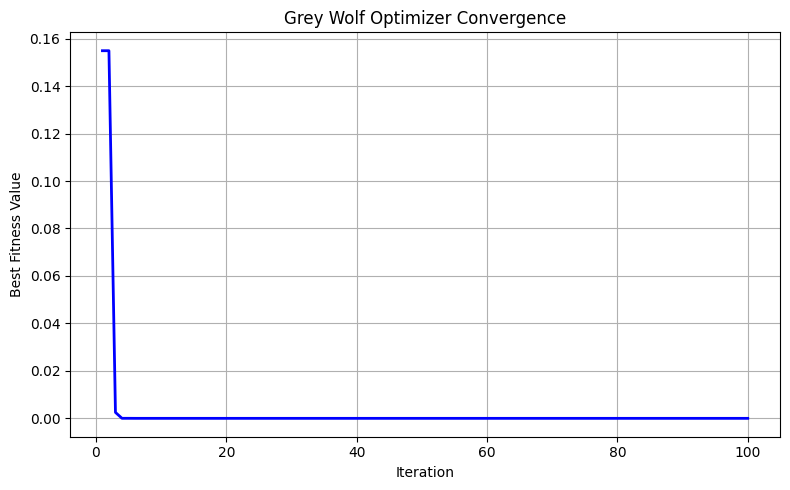

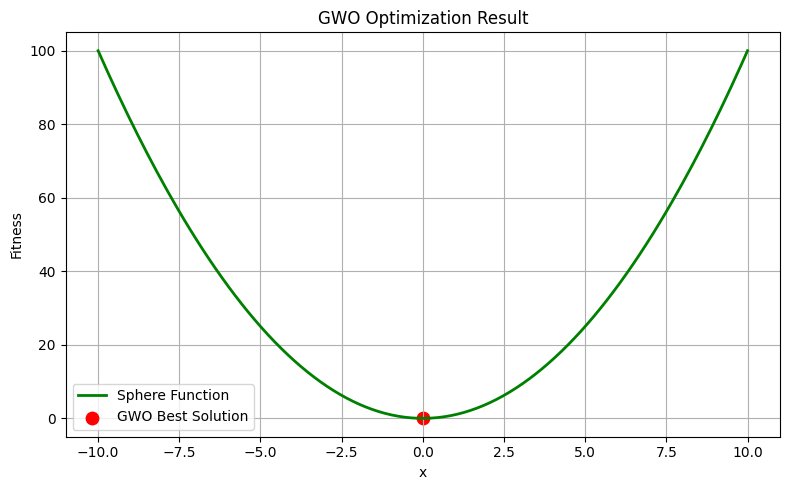

In [2]:

import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# GREY WOLF OPTIMIZER (GWO)
# Minimize Sphere Function: f(x) = sum(x^2)
# ============================================================

# 1. Objective Function
def objective(x):
    return np.sum(x**2)


# 2. Initialize GWO Parameters
lower = -10
upper = 10
dim = 1
wolves = 30
iterations = 100


# 3. Initialize Wolf Population
X = np.random.uniform(
    lower, upper, (wolves, dim)
)


# Initialize Alpha, Beta and Delta
alpha = np.zeros(dim)
beta = np.zeros(dim)
delta = np.zeros(dim)

alpha_score = float("inf")
beta_score = float("inf")
delta_score = float("inf")

# Store convergence history
history = []


# ============================================================
# 4. MAIN GWO LOOP
# ============================================================

for t in range(iterations):

    # Evaluate fitness of every wolf
    for i in range(wolves):

        fitness = objective(X[i])

        # Update Alpha wolf
        if fitness < alpha_score:

            delta_score = beta_score
            delta = beta.copy()

            beta_score = alpha_score
            beta = alpha.copy()

            alpha_score = fitness
            alpha = X[i].copy()

        # Update Beta wolf
        elif fitness < beta_score:

            delta_score = beta_score
            delta = beta.copy()

            beta_score = fitness
            beta = X[i].copy()

        # Update Delta wolf
        elif fitness < delta_score:

            delta_score = fitness
            delta = X[i].copy()

    # Decrease parameter a from 2 to 0
    a = 2 - 2 * t / iterations

    # Update positions of all wolves
    for i in range(wolves):

        # Influence of Alpha
        A1 = 2 * a * np.random.rand(dim) - a
        C1 = 2 * np.random.rand(dim)

        D_alpha = np.abs(C1 * alpha - X[i])
        X1 = alpha - A1 * D_alpha

        # Influence of Beta
        A2 = 2 * a * np.random.rand(dim) - a
        C2 = 2 * np.random.rand(dim)

        D_beta = np.abs(C2 * beta - X[i])
        X2 = beta - A2 * D_beta

        # Influence of Delta
        A3 = 2 * a * np.random.rand(dim) - a
        C3 = 2 * np.random.rand(dim)

        D_delta = np.abs(C3 * delta - X[i])
        X3 = delta - A3 * D_delta

        # Calculate new wolf position
        X[i] = (X1 + X2 + X3) / 3

        # Apply boundary constraints
        X[i] = np.clip(X[i], lower, upper)

    # Store best fitness
    history.append(alpha_score)


# ============================================================
# 5. FINAL RESULT
# ============================================================

print("\n===================================")
print("GREY WOLF OPTIMIZER RESULTS")
print("===================================")

print("Best position:", alpha)
print("Best fitness:", alpha_score)

print("\nTheoretical Solution:")
print("Global minimum: 0")
print("Optimal position: 0")


# ============================================================
# 6. CONVERGENCE GRAPH
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, iterations + 1),
    history,
    color='blue',
    linewidth=2
)

plt.title("Grey Wolf Optimizer Convergence")
plt.xlabel("Iteration")
plt.ylabel("Best Fitness Value")

plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 7. OBJECTIVE FUNCTION GRAPH
# ============================================================

x_values = np.linspace(lower, upper, 200)
y_values = x_values**2

plt.figure(figsize=(8, 5))

plt.plot(
    x_values,
    y_values,
    color='green',
    linewidth=2,
    label='Sphere Function'
)

plt.scatter(
    alpha[0],
    alpha_score,
    color='red',
    s=80,
    label='GWO Best Solution'
)

plt.xlabel("x")
plt.ylabel("Fitness")
plt.title("GWO Optimization Result")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
